# Four-Asset Portfolios — Exercises

In this notebook, you will calculate portfolio expected returns, risks and covariances, combine portfolios X and Y, and visualize sets of portfolios. Work through **Exercises 1–5 in order** because later exercises use results from earlier ones.

All expected returns and covariance inputs are expressed on the same time scale. Use NumPy one-dimensional arrays for portfolio weights.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("ggplot")

## Exercise 1 — Expected return and volatility of portfolios X and Y

Using the variance–covariance matrix, the expected asset returns, and the portfolio weights below, calculate the **expected return** and **standard deviation** of portfolios X and Y.

In [2]:
# Given inputs: four assets
covariance_matrix = np.array([
    [0.10, 0.01, 0.03, 0.05],
    [0.01, 0.30, 0.06, -0.04],
    [0.03, 0.06, 0.40, 0.02],
    [0.05, -0.04, 0.02, 0.50]
])

mean_returns = np.array([0.06, 0.08, 0.10, 0.15])
weights_x = np.array([0.2, 0.3, 0.4, 0.1])
weights_y = np.array([0.2, 0.1, 0.1, 0.6])

print("Covariance matrix:\n", covariance_matrix)
print("Expected asset returns:", mean_returns)
print("Weights X:", weights_x)
print("Weights Y:", weights_y)

Covariance matrix:
 [[ 0.1   0.01  0.03  0.05]
 [ 0.01  0.3   0.06 -0.04]
 [ 0.03  0.06  0.4   0.02]
 [ 0.05 -0.04  0.02  0.5 ]]
Expected asset returns: [0.06 0.08 0.1  0.15]
Weights X: [0.2 0.3 0.4 0.1]
Weights Y: [0.2 0.1 0.1 0.6]


### 1.1 Expected returns

For portfolio weights $\mathbf{w}$ and expected asset returns $\boldsymbol{\mu}$:

$$E(R_P)=\mathbf{w}^{\mathsf T}\boldsymbol{\mu}.$$

With one-dimensional NumPy arrays, use `weights @ mean_returns` directly. Calculate `mu_x` and `mu_y`.

In [3]:
# Exercise 1.1 — Calculate the expected returns of X and Y
mu_x = weights_x @ mean_returns
mu_y = weights_y @ mean_returns

print(f"Mean return of portfolio X: {mu_x:.4f}")
print(f"Mean return of portfolio Y: {mu_y:.4f}")

Mean return of portfolio X: 0.0910
Mean return of portfolio Y: 0.1200


### 1.2 Portfolio variances and standard deviations

With the asset covariance matrix $\mathbf{C}$:

$$\sigma_P^2=\mathbf{w}^{\mathsf T}\mathbf{C}\mathbf{w},\qquad \sigma_P=\sqrt{\sigma_P^2}.$$

Calculate `sigma2_x`, `sigma2_y`, `sigma_x` and `sigma_y` using one-dimensional arrays and `@`.

In [4]:
# Exercise 1.2 — Calculate the variances and standard deviations
sigma2_x = weights_x @ covariance_matrix @ weights_x
sigma2_y = weights_y @ covariance_matrix @ weights_y

sigma_x = np.sqrt(sigma2_x)
sigma_y = np.sqrt(sigma2_y)

print(f"Standard deviation of portfolio X: {sigma_x:.4f}")
print(f"Standard deviation of portfolio Y: {sigma_y:.4f}")

Standard deviation of portfolio X: 0.3487
Standard deviation of portfolio Y: 0.4510


## Exercise 2 — Covariance between portfolios X and Y

Determine the covariance between portfolios X and Y using their asset weights and the same asset covariance matrix:

$$\operatorname{Cov}(R_X,R_Y)=\mathbf{w}_X^{\mathsf T}\mathbf{C}\mathbf{w}_Y.$$

Store the result in `covar_XY`.

In [5]:
# Exercise 2 — Calculate the covariance between X and Y
covar_XY = weights_x @ covariance_matrix @ weights_y

print(f"Covariance between X and Y: {covar_XY:.4f}")

Covariance between X and Y: 0.0714


## Exercise 3 — A portfolio combining X and Y

Create a new portfolio with **30% invested in X and 70% invested in Y**. Calculate its expected return and standard deviation. Treat X and Y as the two components of this new portfolio.

### 3.1 New portfolio weights and expected return

Define `new_weights` and `portfolio_means`, then calculate `mu_xy`.

In [6]:
# Exercise 3.1 — Portfolio weights and expected return
new_weights = np.array([0.3, 0.7])
portfolio_means = np.array([mu_x, mu_y])
mu_xy = new_weights @ portfolio_means

print(f"Expected return of the XY portfolio: {mu_xy:.4f}")

Expected return of the XY portfolio: 0.1113


### 3.2 Covariance matrix of X and Y

Build the 2 × 2 covariance matrix `portfolio_cov_matrix` using `sigma2_x`, `sigma2_y` and `covar_XY`.

In [7]:
# Exercise 3.2 — Covariance matrix of X and Y
portfolio_cov_matrix = np.array([
    [sigma2_x, covar_XY],
    [covar_XY, sigma2_y]
])

print(portfolio_cov_matrix)

[[0.1216 0.0714]
 [0.0714 0.2034]]


### 3.3 Standard deviation of the combined portfolio

Use the 2 × 2 covariance matrix to calculate `sigma2_xy` and `sigma_xy`.

In [8]:
# Exercise 3.3 — Portfolio variance and standard deviation
sigma2_xy = new_weights @ portfolio_cov_matrix @ new_weights
sigma_xy = np.sqrt(sigma2_xy)

print(f"Standard deviation of the XY portfolio: {sigma_xy:.4f}")

Standard deviation of the XY portfolio: 0.3750


## Exercise 4 — Opportunity set of combinations of X and Y

Generate **100 portfolios** with the weight in X increasing from 0% to 100%, while the weight in Y is the complement. Calculate their expected returns and standard deviations, and represent them in a risk–return diagram.

### 4.1 Generate the 100 portfolios

Store their expected returns in `means` and their standard deviations in `stds`.

In [9]:
# Exercise 4.1 — Generate 100 combinations
means = []
stds = []

for w_x in np.linspace(0.0, 1.0, 100):
    w_y = 1.0 - w_x
    weights_xy = np.array([w_x, w_y])

    mu_new = weights_xy @ portfolio_means
    sigma2_new = weights_xy @ portfolio_cov_matrix @ weights_xy

    means.append(mu_new)
    stds.append(np.sqrt(sigma2_new))

### 4.2 Plot the combinations and portfolios X and Y

Plot expected return on the vertical axis and standard deviation on the horizontal axis. Mark portfolios X and Y separately.

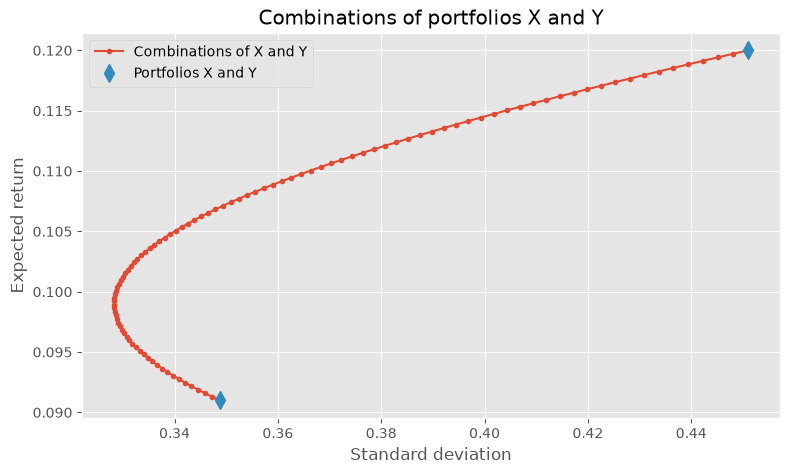

In [10]:
# Exercise 4.2 — Plot 100 combinations plus X and Y
plt.figure(figsize=(9, 5))
plt.plot(stds, means, '.-', label='Combinations of X and Y')
plt.plot([sigma_x, sigma_y], [mu_x, mu_y], 'd', markersize=9,
         label='Portfolios X and Y')
plt.xlabel('Standard deviation')
plt.ylabel('Expected return')
plt.title('Combinations of portfolios X and Y')
plt.legend()
plt.show()

### 4.3 Add the four individual assets

Create another figure that contains the **100 portfolios, X and Y, and the four original assets**.

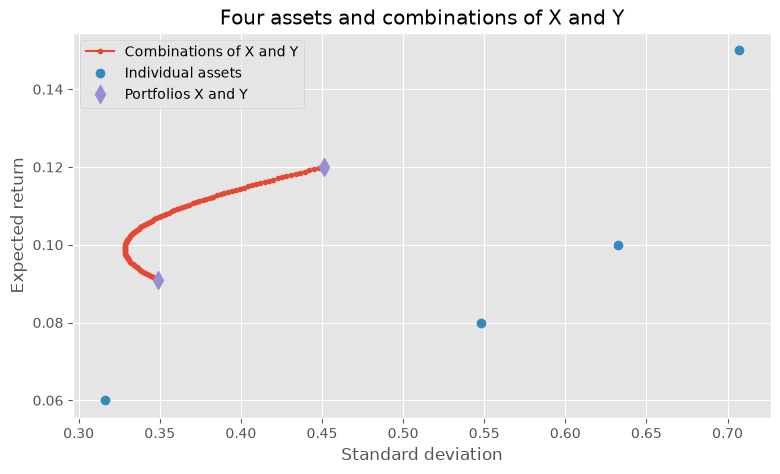

In [11]:
# Exercise 4.3 — Add the four original assets
plt.figure(figsize=(9, 5))
plt.plot(stds, means, '.-', label='Combinations of X and Y')
plt.plot(np.sqrt(np.diag(covariance_matrix)), mean_returns, 'o',
         label='Individual assets')
plt.plot([sigma_x, sigma_y], [mu_x, mu_y], 'd', markersize=9,
         label='Portfolios X and Y')
plt.xlabel('Standard deviation')
plt.ylabel('Expected return')
plt.title('Four assets and combinations of X and Y')
plt.legend()
plt.show()

## Exercise 5 — Random four-asset portfolios

Generate **10,000 long-only portfolios** with random nonnegative weights that add up to one. Calculate the expected return and standard deviation of each portfolio and plot them together with the curve from Exercise 4, portfolios X and Y, and the four individual assets.

### 5.1 Generate random portfolio weights

Use a fixed random seed for reproducibility. Store a matrix of shape `(10000, 4)` in `weights`, with each row summing to one.

In [12]:
# Exercise 5.1 — Generate 10,000 random four-asset portfolios
num_portfolios = 10000
num_assets = 4
rng = np.random.default_rng(42)

weights = rng.random(size=(num_portfolios, num_assets))
weights = weights / weights.sum(axis=1, keepdims=True)

print('Weights matrix shape:', weights.shape)
print('First portfolio weights:', weights[0])

Weights matrix shape: (10000, 4)
First portfolio weights: [0.27952757 0.15850851 0.31009744 0.25186648]


### 5.2 Compute portfolio expected returns and standard deviations

Calculate the expected returns and risks of the 10,000 portfolios. You can compute all variances efficiently with NumPy without constructing a 10,000 × 10,000 matrix.

In [13]:
# Exercise 5.2 — Expected returns and standard deviations
portfolio_returns = weights @ mean_returns
portfolio_variances = np.sum((weights @ covariance_matrix) * weights, axis=1)
portfolio_stds = np.sqrt(portfolio_variances)

print('Number of calculated portfolios:', len(portfolio_returns))

Number of calculated portfolios: 10000


### 5.3 Plot all the portfolios

Plot the **10,000 random four-asset portfolios**, the **100 combinations of X and Y**, **X and Y themselves**, and the **four individual assets** in one risk–return figure.

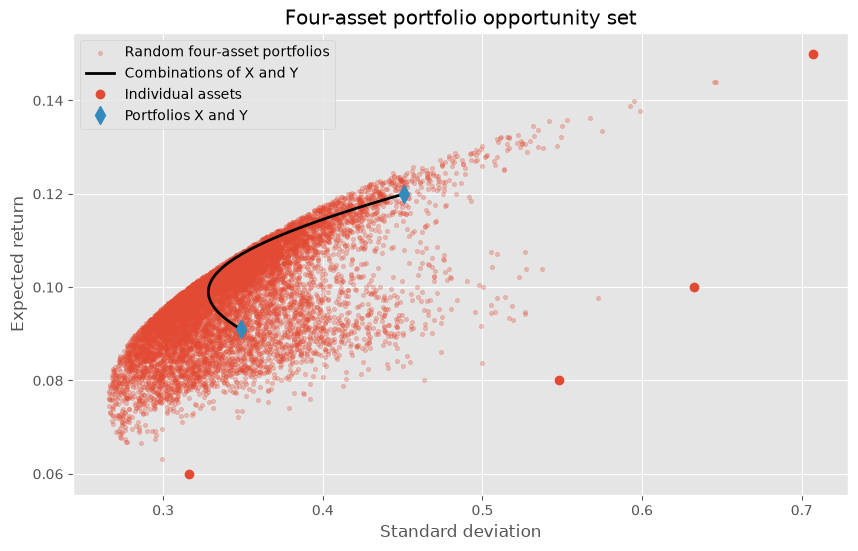

In [14]:
# Exercise 5.3 — Compare the opportunity sets
plt.figure(figsize=(10, 6))
plt.scatter(portfolio_stds, portfolio_returns, marker='.', alpha=0.3,
            label='Random four-asset portfolios')
plt.plot(stds, means, color='black', linewidth=2,
         label='Combinations of X and Y')
plt.plot(np.sqrt(np.diag(covariance_matrix)), mean_returns, 'o',
         label='Individual assets')
plt.plot([sigma_x, sigma_y], [mu_x, mu_y], 'd', markersize=9,
         label='Portfolios X and Y')
plt.xlabel('Standard deviation')
plt.ylabel('Expected return')
plt.title('Four-asset portfolio opportunity set')
plt.legend()
plt.show()

# Exercise — Exploring Portfolio Diversification with Random Portfolios

## Your role

You are a portfolio analyst working for an investment management company. Your manager wants to understand how expanding the investment universe affects the relationship between portfolio risk and expected return.

Your task is to compare the investment opportunities available when constructing portfolios with **4 stocks versus 20 stocks**.

## 1. Download and prepare the data

Download daily **Adjusted Close** prices from Yahoo Finance for the following 20 stocks:

| Ticker | Company | Ticker | Company |
|---|---|---|---|
| AAPL | Apple | MSFT | Microsoft |
| AMZN | Amazon | GOOGL | Alphabet |
| JPM | JPMorgan Chase | BAC | Bank of America |
| JNJ | Johnson & Johnson | PFE | Pfizer |
| KO | Coca-Cola | PG | Procter & Gamble |
| XOM | Exxon Mobil | CVX | Chevron |
| WMT | Walmart | HD | Home Depot |
| CAT | Caterpillar | GE | GE Aerospace |
| NEE | NextEra Energy | SO | Southern Company |
| MCD | McDonald's | DIS | Walt Disney |

**Analysis period:** January 2, 2022, to December 31, 2025, inclusive.

**Data-quality requirements**

Before constructing any portfolios, prepare a common, reliable dataset:

- Exclude stocks for which more than **10% of daily price observations are missing** during the analysis period.
- Use only dates with complete price observations for all remaining stocks.
- Calculate daily log returns from the cleaned prices.
- Use the **same return dates** for all portfolio calculations.

Report how many stocks and trading dates remain after cleaning.

## 2. Exercise A — Portfolios with four stocks

Select the **first four stocks in the list**: AAPL, MSFT, AMZN and GOOGL.

1. Generate **1,000 random portfolios** using these four stocks.
2. Assign random non-negative weights to each portfolio, ensuring that the weights sum to one. Short selling is not allowed.
3. Calculate the **daily returns of each portfolio**.
4. Using an initial investment of 100, calculate and plot the **portfolio value over time for the first 20 randomly generated portfolios**.
5. For each of the 1,000 portfolios, calculate its annualized mean return and annualized volatility.
6. Create a scatter plot with **annualized volatility on the horizontal axis** and **annualized mean return on the vertical axis**, showing all 1,000 portfolios.

## 3. Exercise B — Portfolios with 20 stocks

Repeat the previous exercise using **all the eligible stocks** from the original list of 20.

1. Generate **1,000 new random portfolios**, with non-negative weights summing to one.
2. Calculate the daily returns of each portfolio.
3. Plot the evolution of the portfolio value, starting from 100, for the **first 20 randomly generated portfolios**.
4. Calculate the annualized mean return and annualized volatility of all 1,000 portfolios.
5. Create the same risk–return scatter plot as in Exercise A.

Use the same dates and annualization conventions as in Exercise A.

## 4. Compare your results

Create one final figure showing the risk–return scatter plots of both exercises together, using different colors for the 4-stock and 20-stock portfolios.

Answer the following questions:

1. How does the distribution of portfolio volatilities change when the investment universe expands from 4 to 20 stocks?
2. Does adding more available stocks necessarily reduce the volatility of every randomly generated portfolio?
3. Does the larger investment universe offer opportunities that were not available with only four stocks?
4. Why does generating 1,000 random portfolios not guarantee that you have found the minimum-variance portfolio?

## Financial interpretation

The objective is to understand how the **number and composition of available assets** affect portfolio diversification and the set of attainable risk–return combinations.

Remember that the 1,000 portfolios are randomly generated samples of the investment opportunity set, not necessarily optimal portfolios.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# List of 20 stocks
tickers = [
    "AAPL", "MSFT", "AMZN", "GOOGL",
    "JPM", "BAC", "JNJ", "PFE",
    "KO", "PG", "XOM", "CVX",
    "WMT", "HD", "CAT", "GE",
    "NEE", "SO", "MCD", "DIS"
]

# Download adjusted closing prices
prices = yf.download(
    tickers,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)["Adj Close"]

# Remove stocks with more than 10% missing prices
prices = prices.loc[:, prices.isna().mean() <= 0.10]

# Remove dates with missing prices
prices = prices.dropna()

# Calculate daily log returns
returns = np.log(prices / prices.shift(1)).dropna()

print("Number of stocks:", returns.shape[1])
print("Number of trading days:", len(returns))
display(returns.head())


Number of stocks: 20
Number of trading days: 501


Ticker,AAPL,AMZN,BAC,CAT,CVX,DIS,GE,GOOGL,HD,JNJ,JPM,KO,MCD,MSFT,NEE,PFE,PG,SO,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,
2024-01-03,-0.007516,-0.009786,-0.010974,-0.029153,0.018886,0.010309,-0.015120,0.005414,-0.019961,0.006232,-0.004368,0.002338,-0.008962,-0.000728,0.006798,0.000000,-0.006069,0.019429,0.000063,0.008367
2024-01-04,-0.012781,-0.026619,0.008020,0.006312,-0.011024,-0.011964,0.004825,-0.018380,0.000975,-0.002114,0.006614,-0.003341,-0.009042,-0.007204,-0.003070,-0.021762,0.005464,-0.007363,-0.009714,-0.008758
2024-01-05,-0.004021,0.004624,0.018468,0.009843,-0.001727,0.003747,0.012991,-0.004851,0.012765,0.003108,0.005005,-0.001507,-0.009471,-0.000517,0.004521,0.012978,-0.008309,-0.001395,-0.006678,0.003025
2024-01-08,0.023887,0.026230,-0.007873,0.011425,-0.006002,0.007125,0.015634,0.022655,0.014446,0.002479,-0.001452,0.007347,0.010019,0.018696,0.013440,0.003726,0.008578,0.007651,0.009779,-0.016802
2024-01-09,-0.002266,0.015110,-0.015637,0.000137,-0.025747,-0.020749,0.003890,0.015083,-0.005013,0.000619,-0.007937,-0.001832,-0.003535,0.002932,-0.014569,-0.006104,0.004094,-0.004027,0.006676,-0.012463


In [2]:

# Select the first four stocks
returns_4 = returns.iloc[:, :4]

# Generate 1,000 random portfolios
np.random.seed(42)
n_portfolios = 1000

# Store the portfolio weights
weights_4 = np.random.random((n_portfolios, 4))

# Normalize weights so each portfolio sums to 1
weights_4 = weights_4 / weights_4.sum(axis=1, keepdims=True)

# Daily returns: dates x portfolios
portfolio_returns_4 = returns_4 @ weights_4.T

# Annualized mean returns and volatilities
mean_4 = portfolio_returns_4.mean() * 252
vol_4 = portfolio_returns_4.std() * np.sqrt(252)

print("Daily portfolio returns:")
display(portfolio_returns_4.head())


Daily portfolio returns:


,0,1,2,3,4,5,6,7,8,9,...,990,991,992,993,994,995,996,997,998,999
Date,,,,,,,,,,,,,,,,,,,,,
2024-01-03,-0.014159,-0.023124,-0.017371,-0.011118,-0.013305,-0.014080,-0.014471,-0.011677,-0.015760,-0.015449,...,-0.016137,-0.010762,-0.013924,-0.017752,-0.015111,-0.011105,-0.012827,-0.012063,-0.014065,-0.011895
2024-01-04,-0.007698,-0.000173,-0.008803,-0.009699,-0.008089,-0.004879,-0.011192,-0.002018,-0.004750,0.001161,...,-0.008794,-0.016058,-0.002740,-0.006720,-0.011655,-0.013818,-0.013784,-0.016960,-0.002440,-0.006695
2024-01-05,0.008397,0.007840,0.004689,0.001984,0.007761,0.005097,0.005394,0.007573,0.010730,0.010608,...,0.003660,0.008426,0.009111,0.007447,0.004399,0.003230,0.003143,0.004185,0.006131,0.008347
2024-01-08,0.013163,0.013959,0.019068,0.018523,0.013503,0.014299,0.018307,0.008846,0.010071,0.006210,...,0.019290,0.016562,0.009199,0.015449,0.019871,0.020030,0.021071,0.021728,0.011788,0.011272
2024-01-09,0.000810,0.000982,0.003978,-0.001061,0.000338,-0.002693,0.003979,-0.007140,-0.000286,-0.006454,...,0.002703,0.006186,-0.004184,0.002765,0.004801,0.003261,0.004700,0.007396,-0.004930,-0.002155


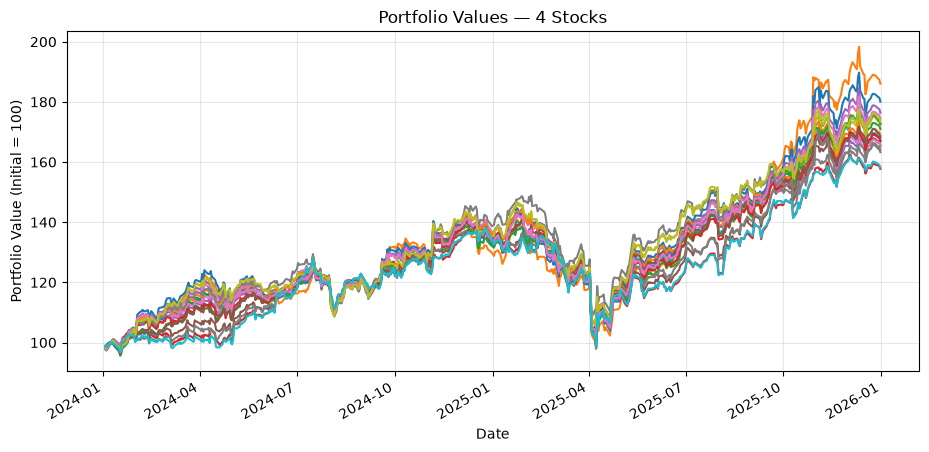

In [3]:

# Portfolio values, starting from 100
values_4 = 100 * np.exp(portfolio_returns_4.cumsum())

# Plot the first 20 portfolios
values_4.iloc[:, :20].plot(figsize=(11, 5), legend=False)

plt.title("Portfolio Values — 4 Stocks")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (Initial = 100)")
plt.grid(True, alpha=0.3)
plt.show()


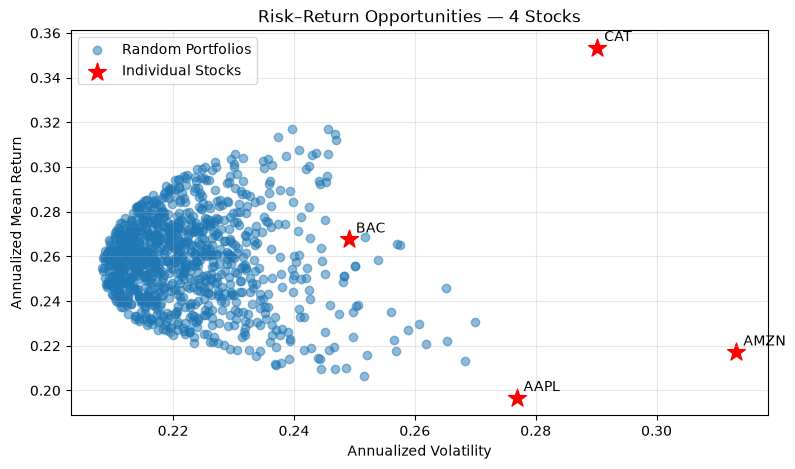

In [4]:
plt.figure(figsize=(9, 5))

# Plot the 1,000 random portfolios
plt.scatter(vol_4, mean_4, alpha=0.5, label="Random Portfolios")

# Calculate annualized returns and volatilities of individual stocks
stock_means = returns_4.mean() * 252
stock_vols = returns_4.std() * np.sqrt(252)

# Add individual stocks
plt.scatter(stock_vols, stock_means, color="red", marker="*", s=180, label="Individual Stocks")

# Add stock labels
for ticker in returns_4.columns:
    plt.annotate(ticker, (stock_vols[ticker], stock_means[ticker]),
                 xytext=(5, 5), textcoords="offset points")

plt.title("Risk–Return Opportunities — 4 Stocks")
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Mean Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

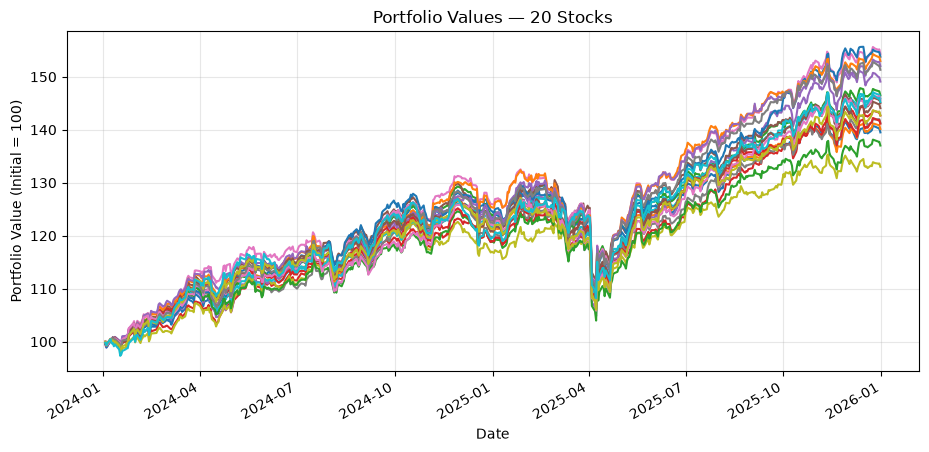

In [5]:

# Number of eligible stocks
n_stocks = returns.shape[1]

# Generate 1,000 random portfolios
weights_20 = np.random.random((n_portfolios, n_stocks))

# Normalize weights
weights_20 = weights_20 / weights_20.sum(axis=1, keepdims=True)

# Calculate daily returns for each portfolio
portfolio_returns_20 = returns @ weights_20.T

# Annualized mean returns and volatilities
mean_20 = portfolio_returns_20.mean() * 252
vol_20 = portfolio_returns_20.std() * np.sqrt(252)

# Portfolio values, starting from 100
values_20 = 100 * np.exp(portfolio_returns_20.cumsum())

# Plot the first 20 portfolios
values_20.iloc[:, :20].plot(figsize=(11, 5), legend=False)

plt.title("Portfolio Values — 20 Stocks")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (Initial = 100)")
plt.grid(True, alpha=0.3)
plt.show()


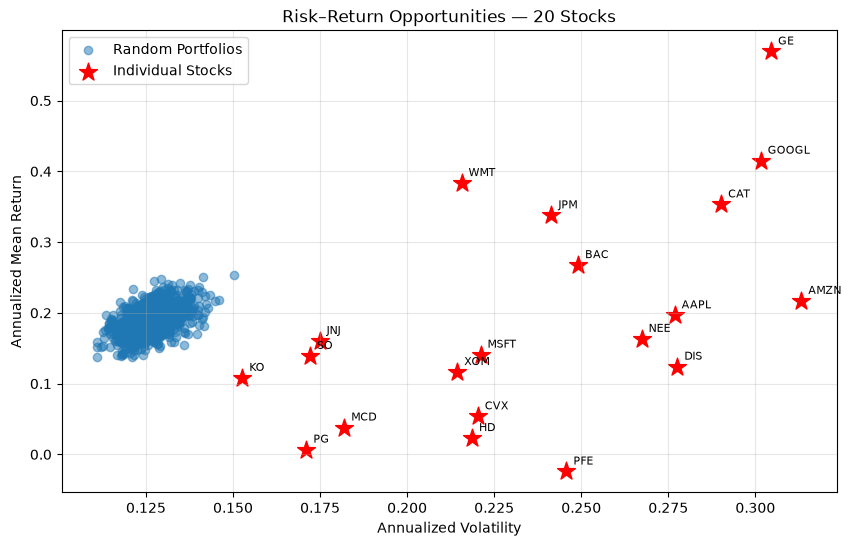

In [6]:

plt.figure(figsize=(10, 6))

# Plot the 1,000 random portfolios
plt.scatter(vol_20, mean_20, alpha=0.5, label="Random Portfolios")

# Calculate annualized returns and volatilities of individual stocks
stock_means = returns.mean() * 252
stock_vols = returns.std() * np.sqrt(252)

# Add individual stocks
plt.scatter(stock_vols, stock_means, color="red", marker="*",
            s=180, label="Individual Stocks")

# Add ticker labels
for ticker in returns.columns:
    plt.annotate(
        ticker,
        (stock_vols[ticker], stock_means[ticker]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title("Risk–Return Opportunities — 20 Stocks")
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Mean Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [9]:

# Difference between maximum and minimum weight in each portfolio
range_4 = weights_4.max(axis=1) - weights_4.min(axis=1)
range_20 = weights_20.max(axis=1) - weights_20.min(axis=1)

# Compare average differences
print(f"4 stocks — Average range: {range_4.mean():.2%}")
print(f"20 stocks — Average range: {range_20.mean():.2%}")

4 stocks — Average range: 33.02%
20 stocks — Average range: 9.15%


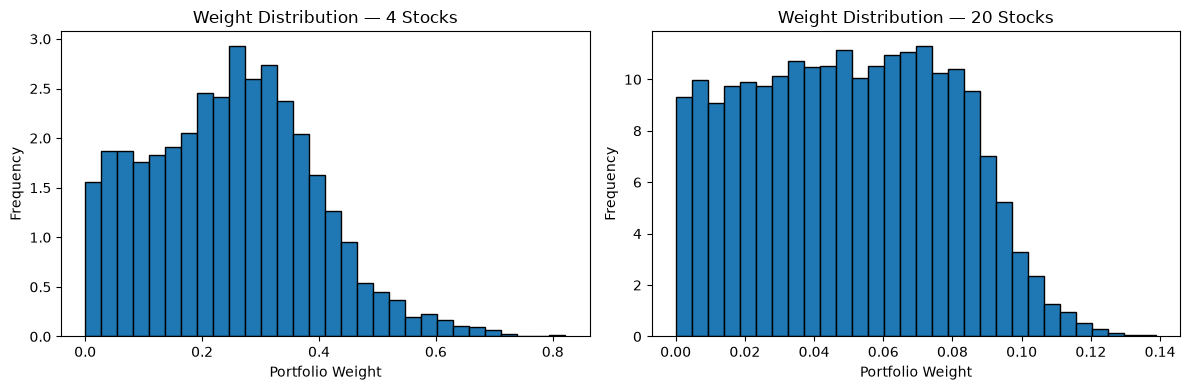

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Weight distribution: 4 stocks
axes[0].hist(weights_4.flatten(), bins=30, edgecolor="black", density=True)
axes[0].set_title("Weight Distribution — 4 Stocks")
axes[0].set_xlabel("Portfolio Weight")
axes[0].set_ylabel("Frequency")

# Weight distribution: 20 stocks
axes[1].hist(weights_20.flatten(), bins=30, edgecolor="black", density=True)
axes[1].set_title("Weight Distribution — 20 Stocks")
axes[1].set_xlabel("Portfolio Weight")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()
